# Tópico 1 - Frequência e Exponenciais Complexas

## Visão Geral e Objetivos
Neste notebook, realizamos a investigação prática de sinais oscilatórios em tempo discreto, abordando os conceitos fundamentais do Estudo Dirigido:
1. **Análise Paramétrica de Senoides**: Estudo do impacto da variação de amplitude ($A$), frequência angular ($\omega_0$) e fase inicial ($\phi$) no sinal discreto $x[n] = A \cos(\omega_0 n + \phi)$.
2. **Exponenciais Complexas e Relação de Euler**: Decomposição da exponencial complexa $e^{j \omega_0 n} = \cos(\omega_0 n) + j \sin(\omega_0 n)$ em suas partes real e imaginária.
3. **Gerenciamento de Resultados**: Salvamento automático das figuras de saída diretamente no diretório de trabalho para documentação.

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para salvar os gráficos
os.makedirs(".", exist_ok=True)

## 1. Variação de Amplitude, Frequência e Fase em Senoides Discretas

Uma senoide discreta é definida matematicamente por $x[n] = A \cos(\omega_0 n + \phi)$.
Abaixo, definimos um vetor de índices de amostragem $n \in [3]$ e analisamos quatro cenários:
- **Sinal Base ($x_1$)**: $A = 1.0$, $\omega_0 = 0.1\pi$ rad/amostra, $\phi = 0.0$ rad
- **Variação de Amplitude ($x_2$)**: $A = 2.0$ (dobro da amplitude base)
- **Variação de Frequência ($x_3$)**: $\omega_0 = 0.3\pi$ rad/amostra (maior taxa de variação por amostra)
- **Variação de Fase ($x_4$)**: $\phi = \pi/4$ rad (deslocamento temporal)

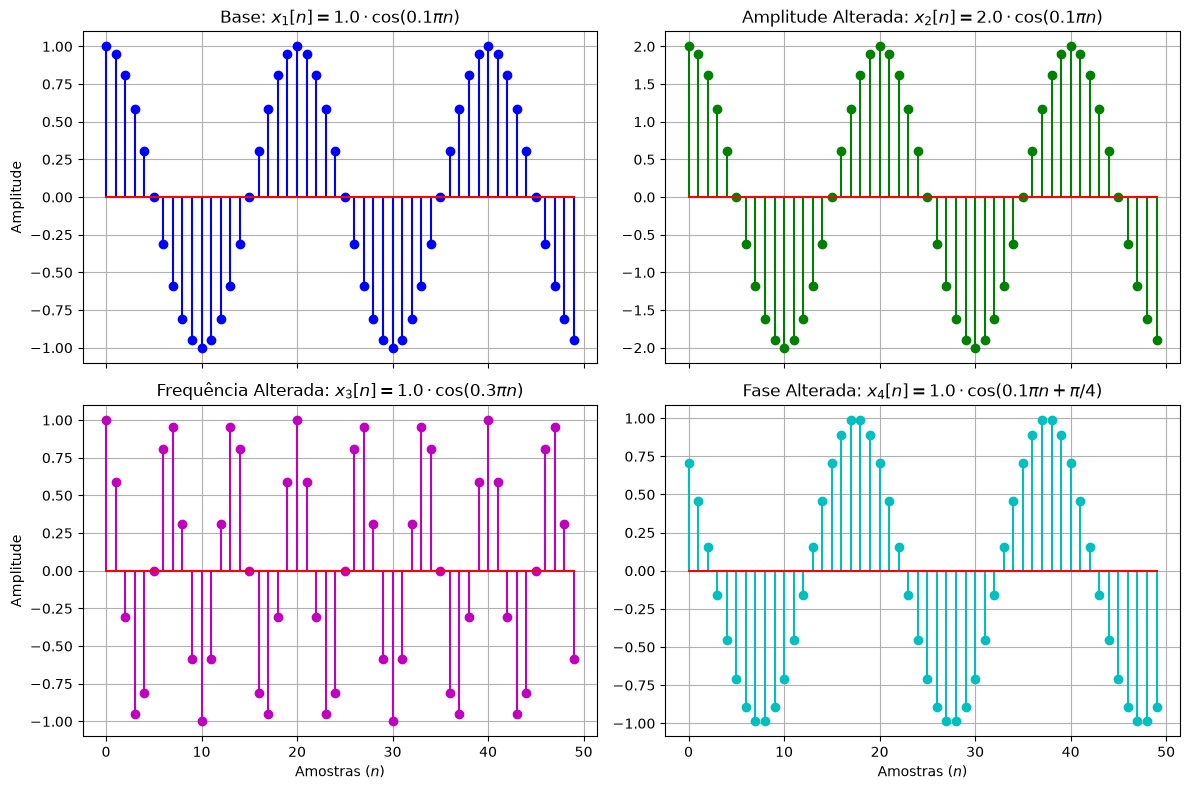

In [4]:
# Domínio discreto (50 amostras)
n = np.arange(0, 50)

# 1. Definição das senoides discretas
x1 = 1.0 * np.cos(0.1 * np.pi * n + 0.0)          # Sinal base
x2 = 2.0 * np.cos(0.1 * np.pi * n + 0.0)          # Amplitude modificada (A=2.0)
x3 = 1.0 * np.cos(0.3 * np.pi * n + 0.0)          # Frequência modificada (w0=0.3*pi)
x4 = 1.0 * np.cos(0.1 * np.pi * n + np.pi / 4.0)  # Fase modificada (phi=pi/4)

# 2. Plotagem em subplots 2x2
fig1, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axs = axs.flatten()  # Converte a matriz 2x2 em uma lista simples de 4 eixos

# Subplot 1: Base
axs[0].stem(n, x1, linefmt='b-', markerfmt='bo', basefmt='r-')
axs[0].set_title(r'Base: $x_1[n] = 1.0 \cdot \cos(0.1\pi n)$')
axs[0].set_ylabel('Amplitude')
axs[0].grid(True)

# Subplot 2: Variação de Amplitude
axs[1].stem(n, x2, linefmt='g-', markerfmt='go', basefmt='r-')
axs[1].set_title(r'Amplitude Alterada: $x_2[n] = 2.0 \cdot \cos(0.1\pi n)$')
axs[1].grid(True)

# Subplot 3: Variação de Frequência
axs[2].stem(n, x3, linefmt='m-', markerfmt='mo', basefmt='r-')
axs[2].set_title(r'Frequência Alterada: $x_3[n] = 1.0 \cdot \cos(0.3\pi n)$')
axs[2].set_xlabel('Amostras ($n$)')
axs[2].set_ylabel('Amplitude')
axs[2].grid(True)

# Subplot 4: Variação de Fase
axs[3].stem(n, x4, linefmt='c-', markerfmt='co', basefmt='r-')
axs[3].set_title(r'Fase Alterada: $x_4[n] = 1.0 \cdot \cos(0.1\pi n + \pi/4)$')
axs[3].set_xlabel('Amostras ($n$)')
axs[3].grid(True)

plt.tight_layout()

# Salvamento do gráfico no diretório corrente
fig1.savefig("grafico_senoides_variacao.png")
plt.show()

## 2. Exponencial Complexa e Relação de Euler

A Relação de Euler estabelece que:
$$e^{j \theta} = \cos(\theta) + j \sin(\theta)$$

Para uma exponencial complexa em tempo discreto $x[n] = e^{j \omega_0 n}$:
- **Parte Real**: $\text{Re}\{e^{j \omega_0 n}\} = \cos(\omega_0 n)$
- **Parte Imaginária**: $\text{Im}\{e^{j \omega_0 n}\} = \sin(\omega_0 n)$

Abaixo, geramos o sinal complexo com $\omega_0 = 0.1\pi$ e plotamos suas partes real e imaginária separadamente.

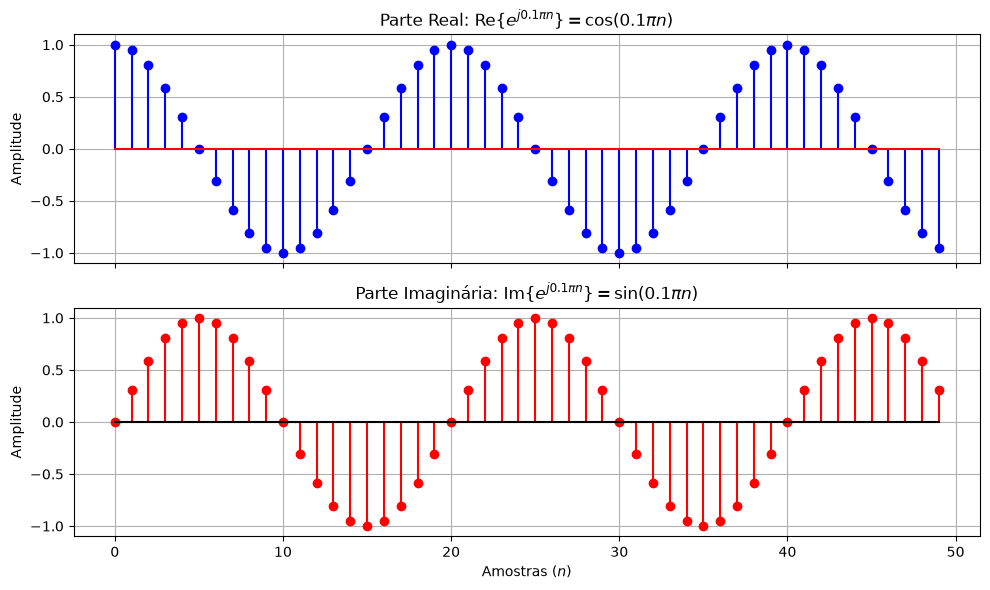

In [5]:
# Frequência angular discreta
w0 = 0.1 * np.pi

# Geração da exponencial complexa e^{j w0 n}
exp_complexa = np.exp(1j * w0 * n)

# Extração da Parte Real e Parte Imaginária
parte_real = np.real(exp_complexa)
parte_imag = np.imag(exp_complexa)

# Plotagem comparativa
fig2, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Gráfico da Parte Real (Cosseno)
ax1.stem(n, parte_real, linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title(r'Parte Real: $\text{Re}\{e^{j 0.1\pi n}\} = \cos(0.1\pi n)$')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

# Gráfico da Parte Imaginária (Seno)
ax2.stem(n, parte_imag, linefmt='r-', markerfmt='ro', basefmt='k-')
ax2.set_title(r'Parte Imaginária: $\text{Im}\{e^{j 0.1\pi n}\} = \sin(0.1\pi n)$')
ax2.set_xlabel('Amostras ($n$)')
ax2.set_ylabel('Amplitude')
ax2.grid(True)

plt.tight_layout()

# Salvamento do gráfico no diretório corrente
fig2.savefig("grafico_exponencial_complexa.png")
plt.show()

## 3. Conclusões da Simulação
- **Amplitude ($A$)**: Define a escala vertical do sinal (picos variando de $-A$ a $+A$).
- **Frequência ($\omega_0$)**: Determina a velocidade de variação entre amostras consecutivas. Com $\omega_0 = 0.3\pi$, observamos um número maior de ciclos no mesmo intervalo de amostras $n$.
- **Fase ($\phi$)**: Provoca um deslocamento horizontal na forma de onda.
- **Decomposição Euleriana**: A parte real corresponde exatamente à função cosseno, enquanto a parte imaginária corresponde à função seno com defasagem de $90^\circ$ ($\pi/2$ rad).